In [1]:
!pip install -q pandas scikit-learn matplotlib seaborn

In [3]:
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/creditcard.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
print("\nFirst 5 transactions:")
display(df.head())

# Check column names and data types
print("\nDataset information:")
df.info()

# Count legitimate and fraudulent transactions
print("\nTransaction class counts:")
print(df["Class"].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset loaded successfully!
Dataset shape: (284807, 31)

First 5 transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

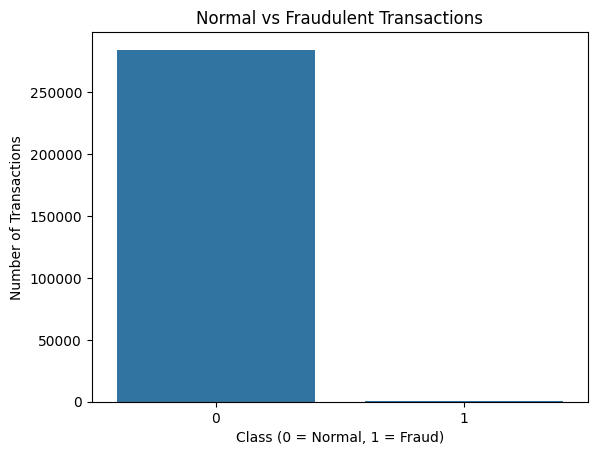

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count normal and fraudulent transactions
sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()


In [6]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())


Training data shape: (227845, 30)
Testing data shape: (56962, 30)

Training class counts:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class counts:
Class
0    56864
1       98
Name: count, dtype: int64


In [7]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [8]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Scale features and train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



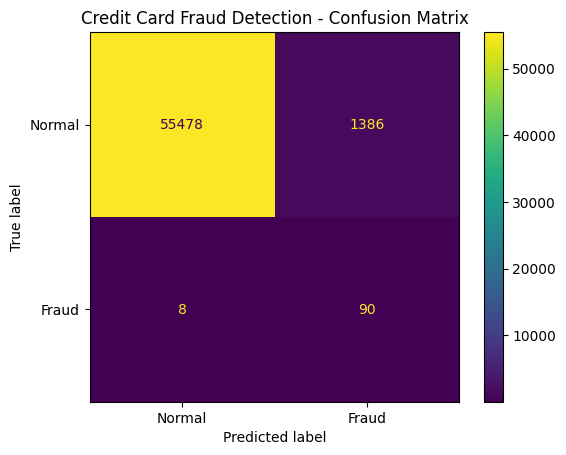

In [9]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict test transactions
y_pred = model.predict(X_test)

# Display evaluation results
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

disp.plot()
plt.title("Credit Card Fraud Detection - Confusion Matrix")
plt.show()


In [10]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))


Accuracy : 0.9755
Precision: 0.061
Recall   : 0.9184
F1-Score : 0.1144


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



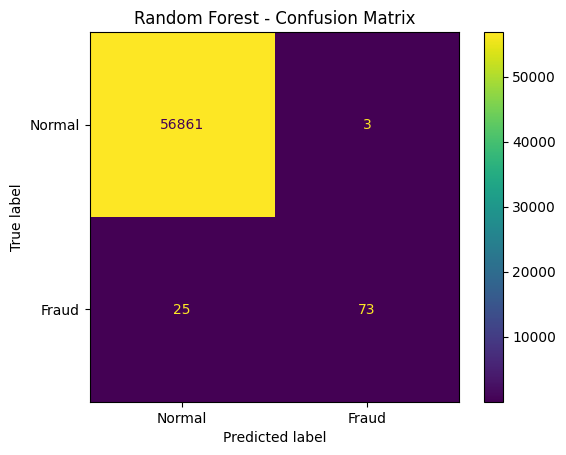

In [11]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create and train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict test transactions
rf_pred = rf_model.predict(X_test)

# Display evaluation results
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

# Plot confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Normal", "Fraud"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()


In [12]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

print(results.round(4).to_string(index=False))


   Metric  Logistic Regression  Random Forest
 Accuracy               0.9755         0.9995
Precision               0.0610         0.9605
   Recall               0.9184         0.7449
 F1-Score               0.1144         0.8391


In [13]:

import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "credit_card_fraud_model.joblib")

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [14]:

from google.colab import files

files.download("credit_card_fraud_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>